# Notebook 01: Gradient Descent Fundamentals

**Gradient Descent (GD)** is the universal optimization engine powering classical machine learning
and deep neural networks. In this notebook, we master its mechanics from the ground up:

1. **Pure Optimization on Arbitrary Functions:** Tracking step trajectories with `minimize_gd`.
2. **3D Loss Landscapes & 2D Contours:** Visualizing the convex quadratic paraboloid bowl and proving gradient orthogonality ($-\nabla J \perp$ level sets).
3. **Spectral Learning Rate Regimes:** Analyzing the Hessian maximum eigenvalue $\lambda_{\max}$ and divergence boundary $\alpha_{\text{crit}} = \frac{2}{\lambda_{\max}}$.
4. **Batch vs. Mini-Batch vs. Stochastic GD:** Comparing deterministic descent, low-variance mini-batches, and stochastic noise orbits.
5. **Feature Scaling & Condition Number $\kappa(\mathbf{H})$:** How unstandardized features stretch loss surfaces into narrow canyons and cause violent zig-zagging.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Ensure src/ is importable
REPO_DIR = Path.cwd()
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from src.gd_engine import (
    LinearRegressionGD,
    MinMaxScalerScratch,
    StandardScalerScratch,
    closed_form_linear,
    minimize_gd,
    quadratic_hessian_spectrum,
)
from src.plot_theme import (
    AMBER,
    BG_CANVAS,
    CMAP_SURFACE,
    CORAL,
    CYAN,
    EMERALD,
    MAGENTA,
    PURPLE,
    SLATE_BLUE,
    TEXT_MUTED,
    apply_github_dark_style,
    save_fig,
    style_3d_axis,
)

apply_github_dark_style()
np.set_printoptions(precision=4, suppress=True)

## 1. 3D Paraboloid Loss Surface & Orthogonal Gradient Field (`01_cost_surface_3d_and_contours.png`)

We generate a univariate linear regression dataset $y = 2.6 x - 1.2 + \epsilon$ ($m=80$) and evaluate
the Mean Squared Error cost function:

$$J(w, b) = \frac{1}{2m}\sum_{i=1}^m (w x^{(i)} + b - y^{(i)})^2$$

over a dense parameter meshgrid of $(w, b)$. We trace Batch Gradient Descent from an off-center
initialization $(w^{(0)} = -2.8, b^{(0)} = 3.4)$ and verify:
- In 3D, the loss surface is a convex paraboloid bowl.
- In 2D, the negative gradient $-\nabla J$ is strictly perpendicular to the iso-cost contour lines.
- Across epochs, the regression line rotates and shifts into the data points.

Analytical Optimum: w* = 2.6688, b* = -1.2821, Min Cost = 0.1807
Batch GD Final:     w  = 2.6651, b  = -1.2597


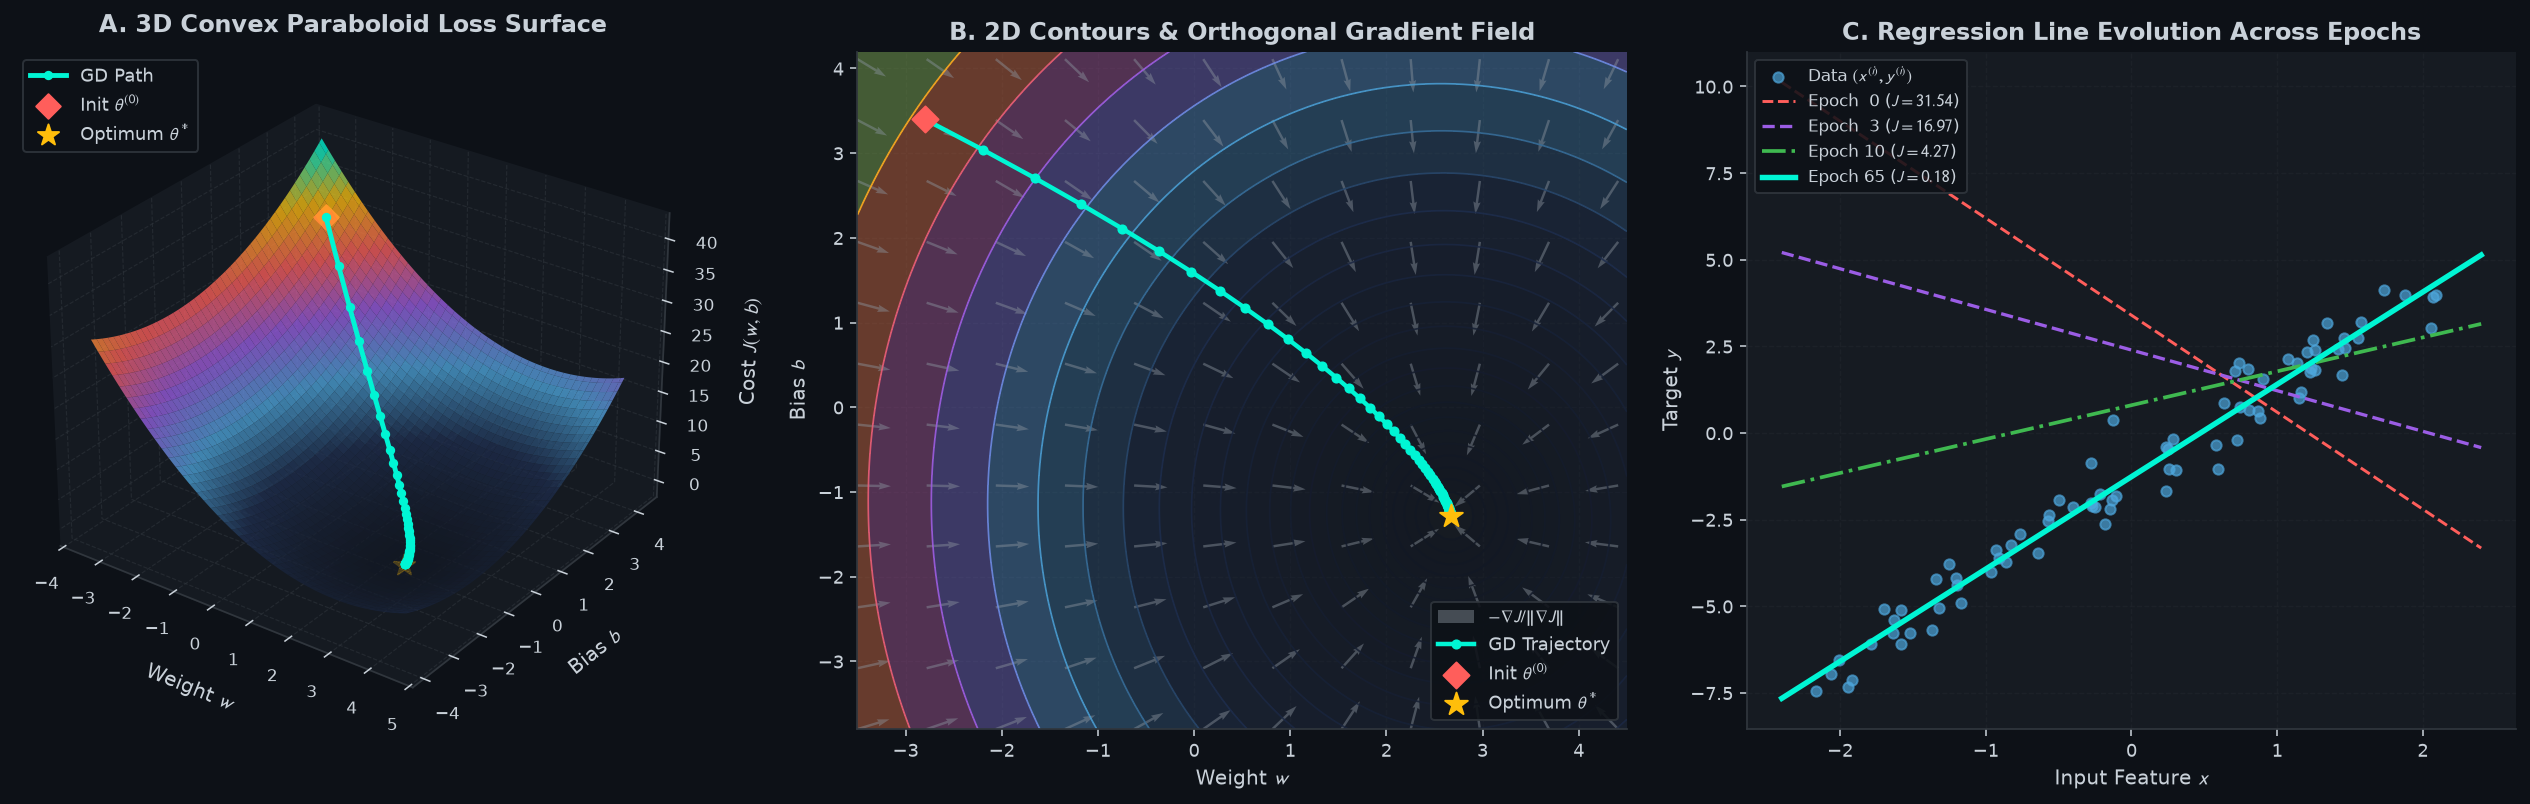

In [2]:
rng = np.random.default_rng(42)
m = 80
X_uni = rng.uniform(-2.2, 2.2, size=(m, 1))
w_true, b_true = 2.6, -1.2
y_uni = w_true * X_uni + b_true + rng.normal(0.0, 0.65, size=(m, 1))

# Fit with Batch Gradient Descent
model_gd = LinearRegressionGD(
    method="batch_gd",
    loss="mse",
    learning_rate=0.08,
    epochs=65,
)
model_gd.fit(X_uni, y_uni, W_init=np.array([[-2.8]]), b_init=3.4)

# Stack trajectory: [w, b, cost]
w_svd, b_svd, _ = closed_form_linear(X_uni, y_uni)
traj_w = np.array([th[0] for th in model_gd.weight_trajectory])
traj_b = np.array([th[1] for th in model_gd.weight_trajectory])
traj_loss = np.array(model_gd.loss_history)

print(f"Analytical Optimum: w* = {w_svd[0, 0]:.4f}, b* = {b_svd:.4f}, Min Cost = {model_gd.loss_history[-1]:.4f}")
print(f"Batch GD Final:     w  = {model_gd.w[0, 0]:.4f}, b  = {model_gd.bias:.4f}")

# Meshgrid over (w, b)
w_grid = np.linspace(-3.5, 4.5, 90)
b_grid = np.linspace(-3.8, 4.2, 90)
W_mesh, B_mesh = np.meshgrid(w_grid, b_grid)
J_mesh = np.zeros_like(W_mesh)

for i in range(W_mesh.shape[0]):
    for j in range(W_mesh.shape[1]):
        preds = X_uni * W_mesh[i, j] + B_mesh[i, j]
        J_mesh[i, j] = 0.5 * np.mean((preds - y_uni) ** 2)

fig = plt.figure(figsize=(18.5, 5.8))

# Panel 1: 3D Loss Bowl
ax1 = fig.add_subplot(1, 3, 1, projection="3d")
style_3d_axis(ax1)
ax1.plot_surface(W_mesh, B_mesh, J_mesh, cmap=CMAP_SURFACE, alpha=0.76, edgecolor="none", rstride=2, cstride=2)
ax1.plot(traj_w, traj_b, traj_loss, color=CYAN, linewidth=2.5, marker="o", markersize=3.8, zorder=10, label="GD Path")
ax1.scatter([traj_w[0]], [traj_b[0]], [traj_loss[0]], color=CORAL, s=80, marker="D", zorder=11, label=r"Init $\theta^{(0)}$")
ax1.scatter([w_svd[0, 0]], [b_svd], [traj_loss[-1]], color=AMBER, s=130, marker="*", zorder=12, label=r"Optimum $\theta^*$")
ax1.set_xlabel("Weight $w$", labelpad=7)
ax1.set_ylabel("Bias $b$", labelpad=7)
ax1.set_zlabel("Cost $J(w, b)$", labelpad=6)
ax1.set_title("A. 3D Convex Paraboloid Loss Surface", pad=10)
ax1.view_init(elev=29, azim=-54)
ax1.legend(loc="upper left")

# Panel 2: 2D Contours & Quiver Field
ax2 = fig.add_subplot(1, 3, 2)
levels = np.geomspace(0.22, float(np.max(J_mesh)), 24)
ax2.contourf(W_mesh, B_mesh, J_mesh, levels=levels, cmap=CMAP_SURFACE, alpha=0.35)
ax2.contour(W_mesh, B_mesh, J_mesh, levels=levels, cmap=CMAP_SURFACE, linewidths=0.9, alpha=0.85)

step_q = 8
Wq, Bq = W_mesh[::step_q, ::step_q], B_mesh[::step_q, ::step_q]
Uw, Ub = np.zeros_like(Wq), np.zeros_like(Bq)
for i in range(Wq.shape[0]):
    for j in range(Wq.shape[1]):
        _, gw, gb = model_gd.compute_cost_and_gradients(X_uni, y_uni, np.array([[Wq[i, j]]]), float(Bq[i, j]))
        norm = np.hypot(gw[0, 0], gb[0, 0]) + 1e-12
        Uw[i, j] = -gw[0, 0] / norm
        Ub[i, j] = -gb[0, 0] / norm

ax2.quiver(Wq, Bq, Uw, Ub, color=TEXT_MUTED, alpha=0.45, scale=23, width=0.0032, label=r"$-\nabla J / \|\nabla J\|$")
ax2.plot(traj_w, traj_b, color=CYAN, linewidth=2.3, marker="o", markersize=4.2, label="GD Trajectory")
ax2.scatter(traj_w[0], traj_b[0], color=CORAL, s=90, marker="D", zorder=6, label=r"Init $\theta^{(0)}$")
ax2.scatter(w_svd[0, 0], b_svd, color=AMBER, s=150, marker="*", zorder=7, label=r"Optimum $\theta^*$")
ax2.set_xlabel("Weight $w$")
ax2.set_ylabel("Bias $b$")
ax2.set_title("B. 2D Contours & Orthogonal Gradient Field")
ax2.legend(loc="lower right")

# Panel 3: Hypothesis Line Evolution
ax3 = fig.add_subplot(1, 3, 3)
x_line = np.linspace(-2.4, 2.4, 200)
ax3.scatter(X_uni[:, 0], y_uni[:, 0], color=SLATE_BLUE, s=28, alpha=0.68, label=r"Data $(x^{(i)}, y^{(i)})$")

snapshot_epochs = [(0, CORAL, "--", 1.5), (3, PURPLE, "--", 1.7), (10, EMERALD, "-.", 1.9), (65, CYAN, "-", 2.8)]
for ep, col, ls, lw in snapshot_epochs:
    w_ep = traj_w[ep]
    b_ep = traj_b[ep]
    j_ep = traj_loss[ep]
    ax3.plot(x_line, w_ep * x_line + b_ep, color=col, linestyle=ls, linewidth=lw, label=f"Epoch {ep:2d} ($J={j_ep:.2f}$)")

ax3.set_xlabel("Input Feature $x$")
ax3.set_ylabel("Target $y$")
ax3.set_title("C. Regression Line Evolution Across Epochs")
ax3.legend(loc="upper left", fontsize=8.5)

fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "01_cost_surface_3d_and_contours.png")
plt.show()

## 2. Spectral Learning Rate Regimes ($\alpha$ vs. $2/\lambda_{\max}$) (`02_learning_rate_regimes.png`)

On a quadratic objective with Hessian $\mathbf{H}$, the error dynamics along the eigenvector
of maximum curvature are governed by:

$$e_{t+1} = (1 - \alpha \lambda_{\max}) e_t$$

This establishes four distinct operational regimes:
1. **Glacial Crawl ($\alpha \ll 1/\lambda_{\max}$):** Monotonic but agonizingly slow convergence.
2. **Optimal Descent ($\alpha \approx 2/(\lambda_{\min} + \lambda_{\max})$):** Fastest contraction without overshooting.
3. **Oscillatory Bouncing ($1/\lambda_{\max} < \alpha < 2/\lambda_{\max}$):** Alternating signs across the ravine walls.
4. **Supercritical Divergence ($\alpha > 2/\lambda_{\max}$):** $|1 - \alpha \lambda_{\max}| > 1$, causing geometric step explosion to $\infty$.

Hessian Spectrum: lambda_min = 0.9991, lambda_max = 3.0973
Optimal Learning Rate:    alpha_opt  = 0.4882
Divergence Boundary:      alpha_crit = 0.6457


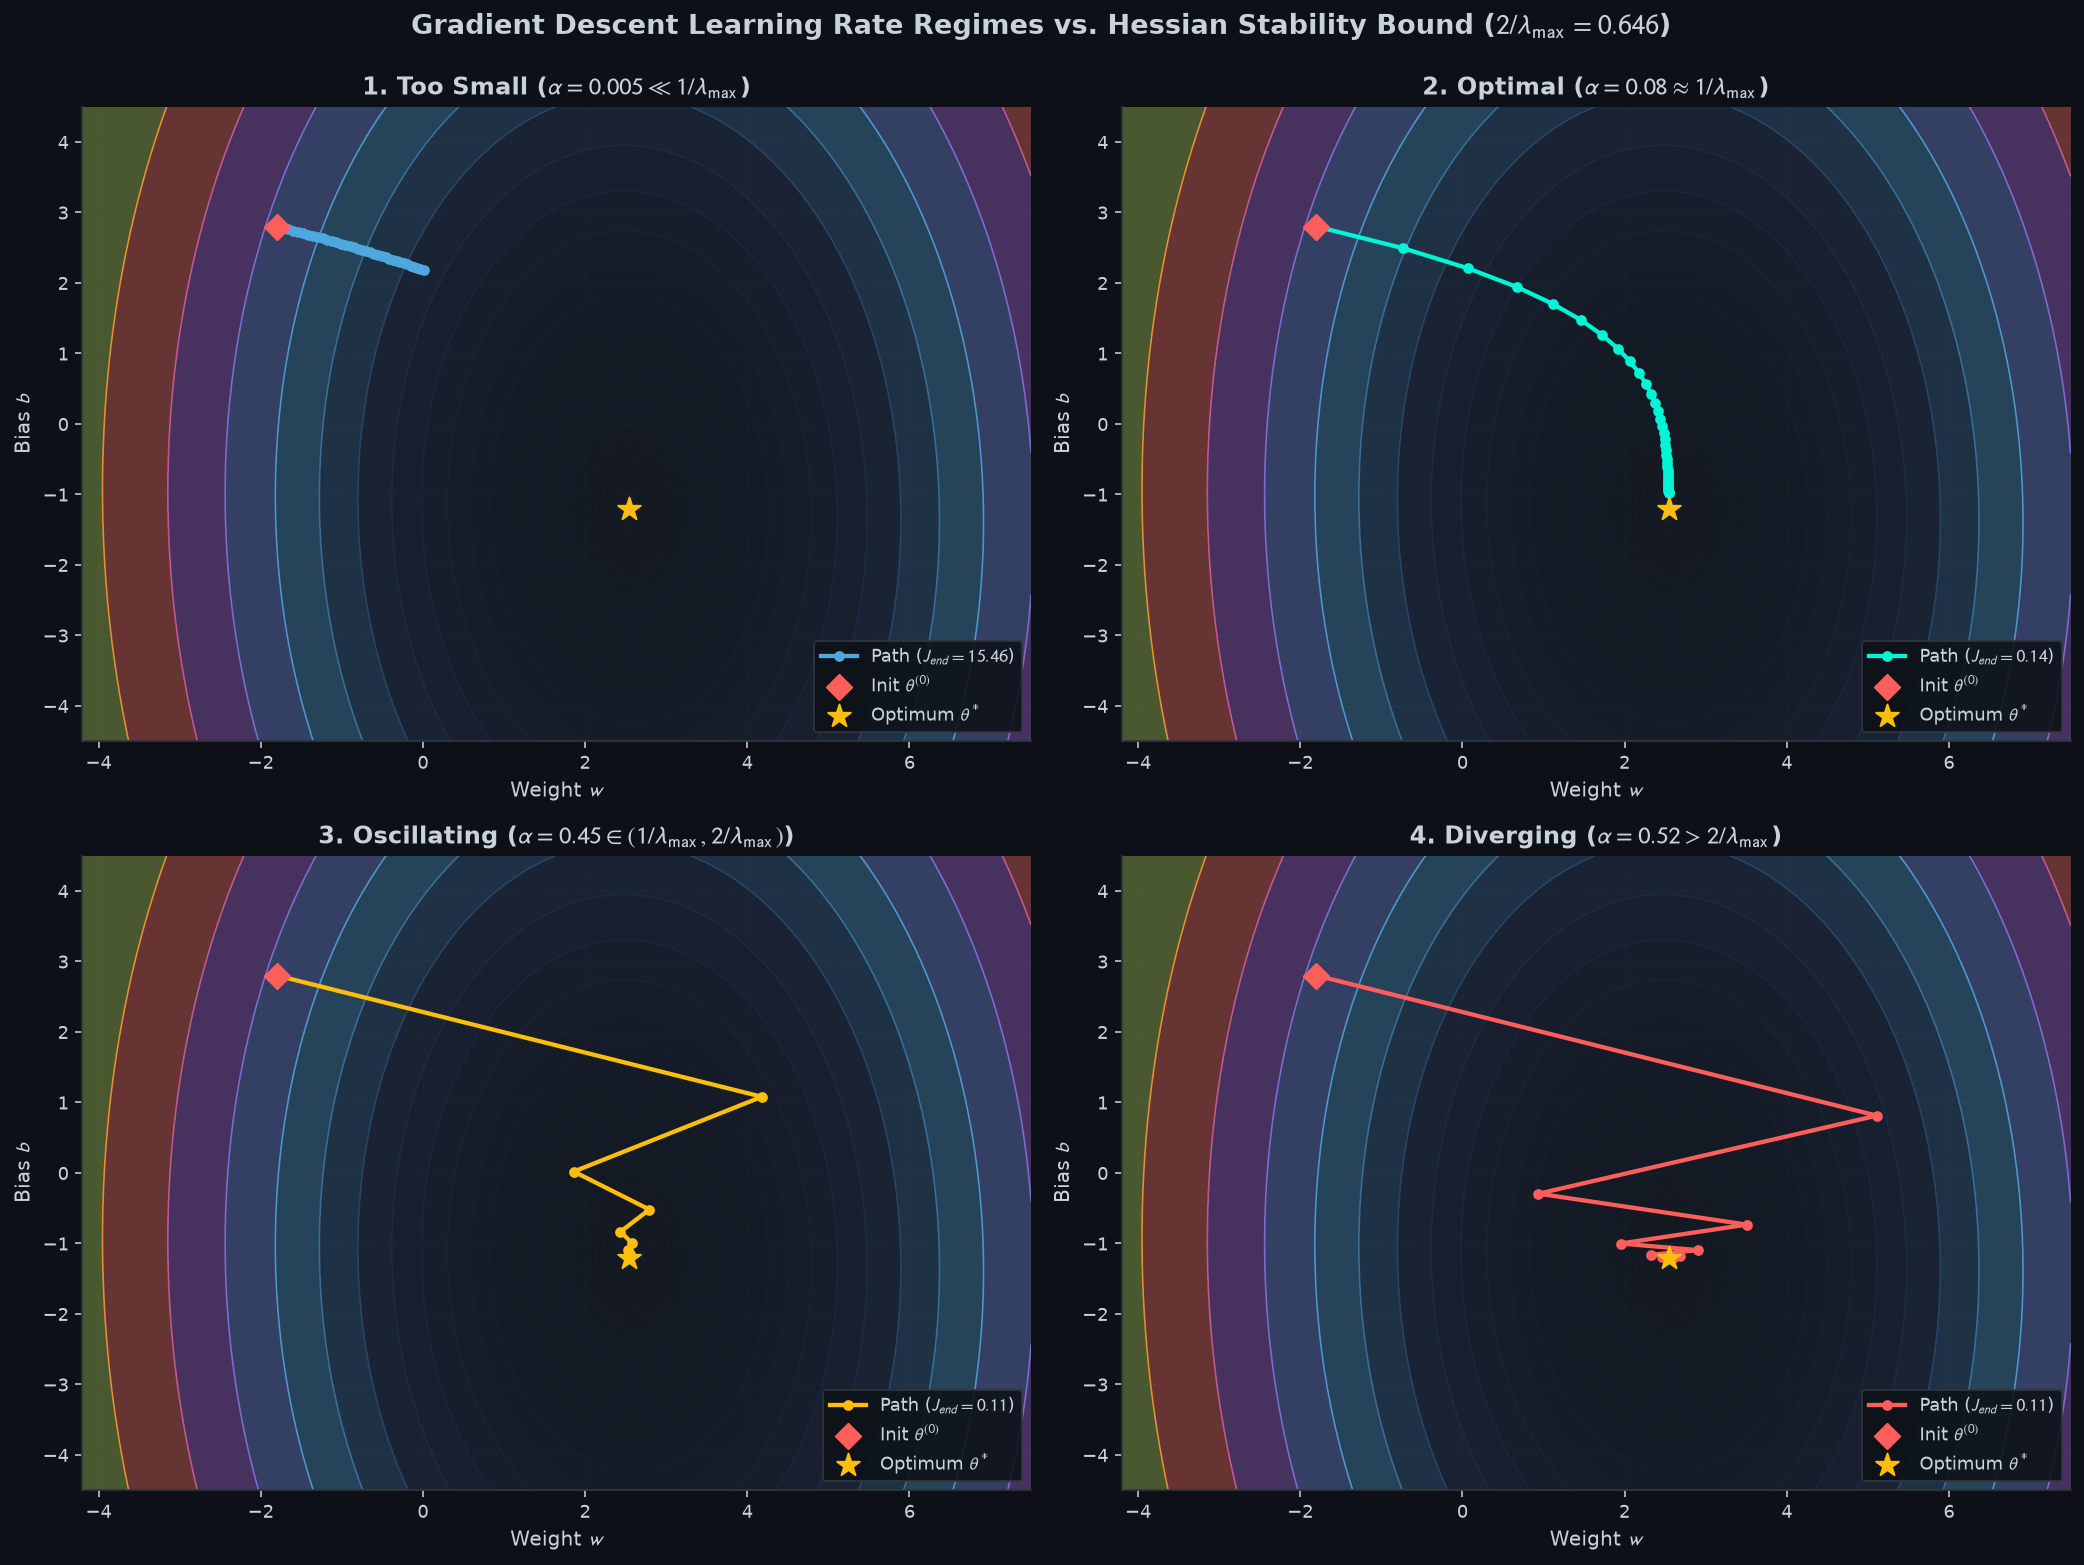

In [3]:
X_lr = X_uni * 1.48
y_lr = w_true * X_lr + b_true + rng.normal(0.0, 0.5, size=(m, 1))

spec = quadratic_hessian_spectrum(X_lr, fit_intercept=True)
lam_min = spec["lambda_min"]
lam_max = spec["lambda_max"]
alpha_crit = spec["alpha_crit"]
alpha_opt = spec["alpha_opt"]

print(f"Hessian Spectrum: lambda_min = {lam_min:.4f}, lambda_max = {lam_max:.4f}")
print(f"Optimal Learning Rate:    alpha_opt  = {alpha_opt:.4f}")
print(f"Divergence Boundary:      alpha_crit = {alpha_crit:.4f}")

regimes = [
    (r"1. Too Small ($\alpha = 0.005 \ll 1/\lambda_{\max}$)", 0.005, 35, SLATE_BLUE),
    (r"2. Optimal ($\alpha = 0.08 \approx 1/\lambda_{\max}$)", 0.08, 35, CYAN),
    (r"3. Oscillating ($\alpha = 0.45 \in (1/\lambda_{\max}, 2/\lambda_{\max})$)", 0.45, 28, AMBER),
    (r"4. Diverging ($\alpha = 0.52 > 2/\lambda_{\max}$)", 0.52, 11, CORAL),
]

w_r = np.linspace(-4.2, 7.5, 100)
b_r = np.linspace(-4.5, 4.5, 100)
W_rm, B_rm = np.meshgrid(w_r, b_r)
J_rm = np.zeros_like(W_rm)
for i in range(W_rm.shape[0]):
    for j in range(W_rm.shape[1]):
        J_rm[i, j] = 0.5 * np.mean((X_lr * W_rm[i, j] + B_rm[i, j] - y_lr) ** 2)

w_lr_star, b_lr_star, _ = closed_form_linear(X_lr, y_lr)

fig, axes = plt.subplots(2, 2, figsize=(15.0, 11.2))
levels_rm = np.geomspace(0.15, float(np.max(J_rm)), 25)

for ax, (title, alpha_val, n_ep, col) in zip(axes.ravel(), regimes):
    m_run = LinearRegressionGD(method="batch_gd", learning_rate=alpha_val, epochs=n_ep)
    m_run.fit(X_lr, y_lr, W_init=np.array([[-1.8]]), b_init=2.8)
    
    tr_w = [th[0] for th in m_run.weight_trajectory]
    tr_b = [th[1] for th in m_run.weight_trajectory]

    ax.contourf(W_rm, B_rm, J_rm, levels=levels_rm, cmap=CMAP_SURFACE, alpha=0.34)
    ax.contour(W_rm, B_rm, J_rm, levels=levels_rm, cmap=CMAP_SURFACE, linewidths=0.85, alpha=0.8)
    ax.plot(tr_w, tr_b, color=col, linewidth=2.2, marker="o", markersize=4.5, label=f"Path ($J_{{end}}={m_run.loss_history[-1]:.2f}$)")
    ax.scatter(tr_w[0], tr_b[0], color=CORAL, s=85, marker="D", zorder=6, label=r"Init $\theta^{(0)}$")
    ax.scatter(w_lr_star[0, 0], b_lr_star, color=AMBER, s=150, marker="*", zorder=7, label=r"Optimum $\theta^*$")
    ax.set_xlim(-4.2, 7.5)
    ax.set_ylim(-4.5, 4.5)
    ax.set_xlabel("Weight $w$")
    ax.set_ylabel("Bias $b$")
    ax.set_title(title)
    ax.legend(loc="lower right")

fig.suptitle(
    rf"Gradient Descent Learning Rate Regimes vs. Hessian Stability Bound ($2/\lambda_{{\max}} = {alpha_crit:.3f}$)",
    fontsize=14,
    fontweight="bold",
    y=0.995,
)
fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "02_learning_rate_regimes.png")
plt.show()

## 3. Batch vs. Mini-Batch vs. Stochastic Gradient Descent (`03_batch_vs_minibatch_vs_sgd.png`)

We compare the trajectory behavior of:
- **Batch GD ($B = m$):** Smooth, deterministic path pointing directly down the gradient of the full dataset.
- **Mini-Batch GD ($B = 24$):** Balanced variance reduction, low noise, high throughput.
- **Stochastic GD ($B = 1$):** High stochasticity, erratic wandering, orbits within a noise ball around $\mathbf{w}^*$.

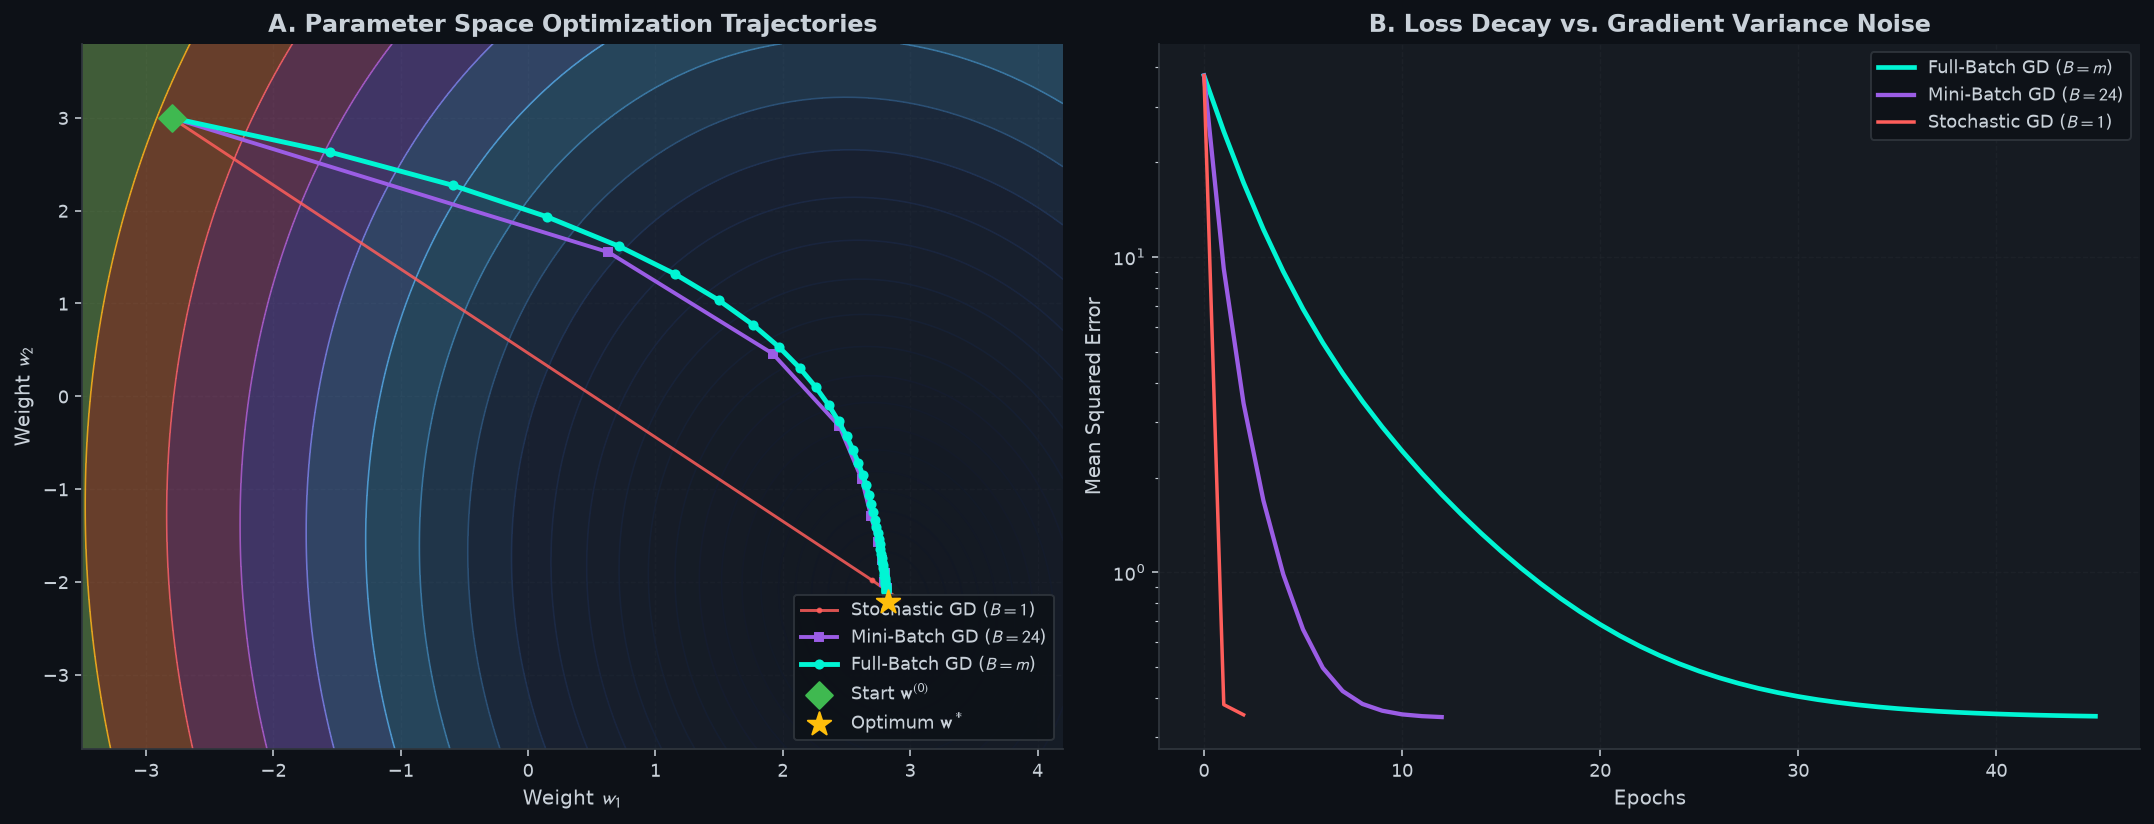

In [4]:
m_tr = 240
X_2d = rng.normal(size=(m_tr, 2))
X_2d[:, 0] *= 1.35
X_2d[:, 1] *= 0.85
w_true_2d = np.array([[2.8], [-2.2]])
y_2d = X_2d @ w_true_2d + rng.normal(0.0, 0.8, size=(m_tr, 1))

w0_init = np.array([[-2.8], [3.0]])

m_batch = LinearRegressionGD(method="batch_gd", learning_rate=0.12, epochs=45).fit(X_2d, y_2d, W_init=w0_init, b_init=0.0)
m_mini = LinearRegressionGD(
    method="minibatch_gd", batch_size=24, learning_rate=0.05, epochs=12, random_state=7
).fit(X_2d, y_2d, W_init=w0_init, b_init=0.0)
m_sgd = LinearRegressionGD(
    method="sgd", learning_rate=0.018, epochs=2, lr_schedule="inverse_time", lr_decay=0.5, random_state=13
).fit(X_2d, y_2d, W_init=w0_init, b_init=0.0)

w_svd_2d, _, _ = closed_form_linear(X_2d, y_2d)

# 2D contour grid over (w1, w2)
w1_g = np.linspace(-3.5, 4.2, 95)
w2_g = np.linspace(-3.8, 3.8, 95)
W1_m, W2_m = np.meshgrid(w1_g, w2_g)
J_2d = np.zeros_like(W1_m)
for i in range(W1_m.shape[0]):
    for j in range(W1_m.shape[1]):
        w_ij = np.array([[W1_m[i, j]], [W2_m[i, j]]])
        J_2d[i, j] = 0.5 * np.mean((X_2d @ w_ij - y_2d) ** 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 6.0))

levels_2d = np.geomspace(float(np.min(J_2d)) + 0.02, float(np.max(J_2d)), 24)
ax1.contourf(W1_m, W2_m, J_2d, levels=levels_2d, cmap=CMAP_SURFACE, alpha=0.35)
ax1.contour(W1_m, W2_m, J_2d, levels=levels_2d, cmap=CMAP_SURFACE, linewidths=0.85, alpha=0.8)

tr_b = np.array([[th[0], th[1]] for th in m_batch.weight_trajectory])
tr_m = np.array([[th[0], th[1]] for th in m_mini.weight_trajectory])
tr_s = np.array([[th[0], th[1]] for th in m_sgd.weight_trajectory])

ax1.plot(tr_s[:, 0], tr_s[:, 1], color=CORAL, linewidth=1.5, alpha=0.85, marker=".", markersize=4, label="Stochastic GD ($B=1$)")
ax1.plot(tr_m[:, 0], tr_m[:, 1], color=PURPLE, linewidth=2.0, marker="s", markersize=4, label="Mini-Batch GD ($B=24$)")
ax1.plot(tr_b[:, 0], tr_b[:, 1], color=CYAN, linewidth=2.5, marker="o", markersize=4.2, label="Full-Batch GD ($B=m$)")
ax1.scatter(w0_init[0, 0], w0_init[1, 0], color=EMERALD, s=95, marker="D", zorder=7, label=r"Start $\mathbf{w}^{(0)}$")
ax1.scatter(w_svd_2d[0, 0], w_svd_2d[1, 0], color=AMBER, s=160, marker="*", zorder=8, label=r"Optimum $\mathbf{w}^*$")
ax1.set_xlabel("Weight $w_1$")
ax1.set_ylabel("Weight $w_2$")
ax1.set_title("A. Parameter Space Optimization Trajectories")
ax1.legend(loc="lower right")

# Panel B: Loss Histories Comparison
ax2.plot(m_batch.loss_history, color=CYAN, linewidth=2.4, label="Full-Batch GD ($B=m$)")
ax2.plot(m_mini.loss_history, color=PURPLE, linewidth=2.2, label="Mini-Batch GD ($B=24$)")
ax2.plot(m_sgd.loss_history, color=CORAL, linewidth=1.8, label="Stochastic GD ($B=1$)")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Mean Squared Error")
ax2.set_yscale("log")
ax2.set_title("B. Loss Decay vs. Gradient Variance Noise")
ax2.legend(loc="upper right")

fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "03_batch_vs_minibatch_vs_sgd.png")
plt.show()

## 4. Feature Scaling Conditioning & Canyon Stretching (`04_feature_scaling_contour_stretch.png`)

When features differ in magnitude ($x_1 \sim 1$ vs $x_2 \sim 5000$), the Hessian eigenvalues
become wildly disparate ($\lambda_{\max} \gg \lambda_{\min}$), creating an elongated elliptical canyon
with condition number $\kappa = \lambda_{\max}/\lambda_{\min} \gg 1$.
- **Unscaled Features:** The gradient points almost entirely across the steep valley walls, forcing tiny step sizes and violent oscillations.
- **Standardized Features:** $\kappa \approx 1$, the contours are nearly spherical, and the gradient points straight toward $\mathbf{w}^*$.

Unscaled Hessian Condition Number:     kappa = 24.47
Standardized Hessian Condition Number: kappa = 1.39


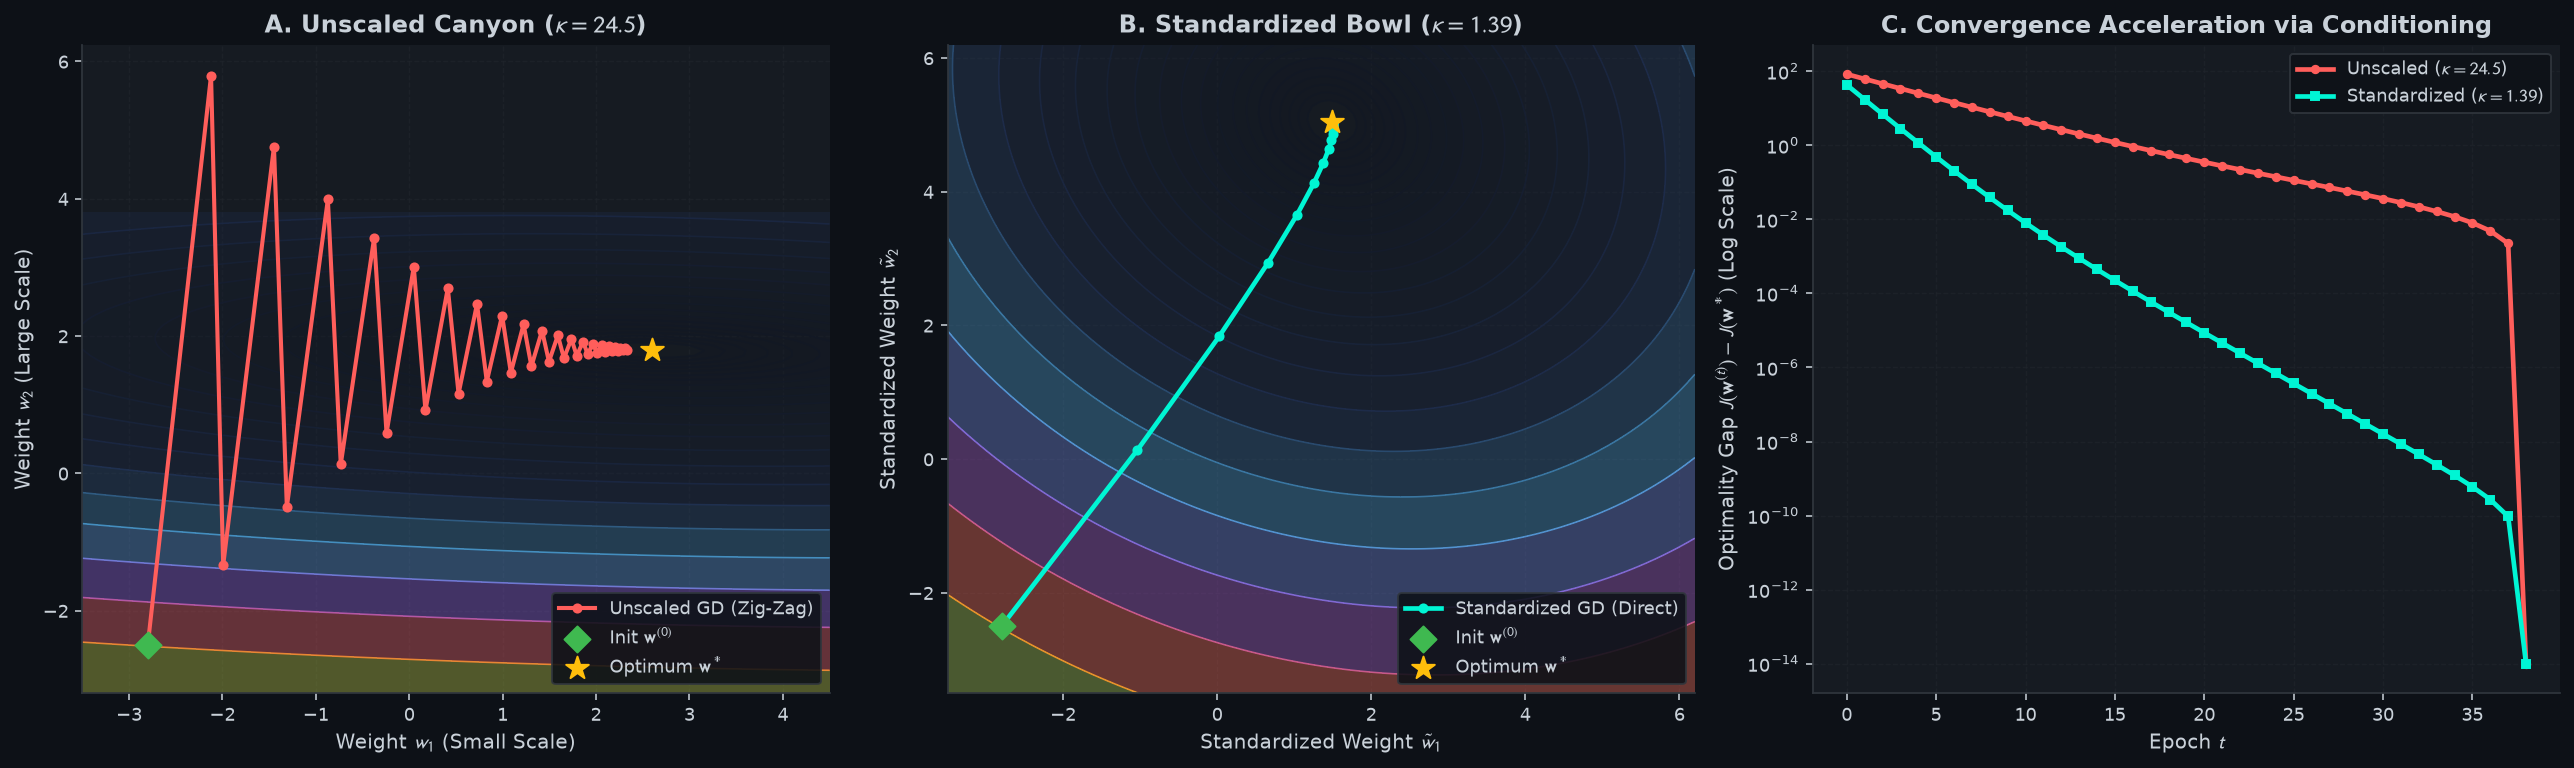

In [5]:
m_s = 160
X_extreme = np.column_stack([rng.normal(0.0, 0.65, size=m_s), rng.normal(0.0, 2.75, size=m_s)])
w_true_vis = np.array([[2.6], [1.8]])
y_vis = X_extreme @ w_true_vis + rng.normal(0.0, 0.4, size=(m_s, 1))

scaler_vis = StandardScalerScratch()
X_scaled_vis = scaler_vis.fit_transform(X_extreme)

# Measure condition numbers
spec_u = quadratic_hessian_spectrum(X_extreme, fit_intercept=False)
spec_s = quadratic_hessian_spectrum(X_scaled_vis, fit_intercept=False)

print(f"Unscaled Hessian Condition Number:     kappa = {spec_u['condition_number']:.2f}")
print(f"Standardized Hessian Condition Number: kappa = {spec_s['condition_number']:.2f}")

gd_unscaled = LinearRegressionGD(method="batch_gd", learning_rate=0.235, epochs=38).fit(
    X_extreme, y_vis, W_init=np.array([[-2.8], [-2.5]]), b_init=0.0
)
w_svd_u, _, _ = closed_form_linear(X_extreme, y_vis)

gd_scaled = LinearRegressionGD(method="batch_gd", learning_rate=0.32, epochs=38).fit(
    X_scaled_vis, y_vis, W_init=np.array([[-2.8], [-2.5]]), b_init=0.0
)
w_svd_s, _, _ = closed_form_linear(X_scaled_vis, y_vis)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18.5, 5.6))

# Panel 1: Unscaled Canyon
w1_u = np.linspace(-3.5, 4.5, 95)
w2_u = np.linspace(-3.2, 3.8, 95)
W1_u, W2_u = np.meshgrid(w1_u, w2_u)
J_u = np.zeros_like(W1_u)
for i in range(W1_u.shape[0]):
    for j in range(W1_u.shape[1]):
        J_u[i, j] = 0.5 * np.mean((X_extreme @ np.array([[W1_u[i, j]], [W2_u[i, j]]]) - y_vis) ** 2)

lev_u = np.geomspace(float(np.min(J_u)) + 0.05, float(np.max(J_u)), 24)
ax1.contourf(W1_u, W2_u, J_u, levels=lev_u, cmap=CMAP_SURFACE, alpha=0.35)
ax1.contour(W1_u, W2_u, J_u, levels=lev_u, cmap=CMAP_SURFACE, linewidths=0.85, alpha=0.82)
tr_u = np.array([[th[0], th[1]] for th in gd_unscaled.weight_trajectory])
ax1.plot(tr_u[:, 0], tr_u[:, 1], color=CORAL, linewidth=2.1, marker="o", markersize=4.2, label="Unscaled GD (Zig-Zag)")
ax1.scatter(tr_u[0, 0], tr_u[0, 1], color=EMERALD, s=90, marker="D", zorder=6, label=r"Init $\mathbf{w}^{(0)}$")
ax1.scatter(w_svd_u[0, 0], w_svd_u[1, 0], color=AMBER, s=150, marker="*", zorder=7, label=r"Optimum $\mathbf{w}^*$")
ax1.set_xlabel("Weight $w_1$ (Small Scale)")
ax1.set_ylabel("Weight $w_2$ (Large Scale)")
ax1.set_title(f"A. Unscaled Canyon ($\kappa = {spec_u['condition_number']:.1f}$)")
ax1.legend(loc="lower right")

# Panel 2: Standardized Bowl
w1_s = np.linspace(-3.5, 6.2, 95)
w2_s = np.linspace(-3.5, 6.2, 95)
W1_s, W2_s = np.meshgrid(w1_s, w2_s)
J_s = np.zeros_like(W1_s)
for i in range(W1_s.shape[0]):
    for j in range(W1_s.shape[1]):
        J_s[i, j] = 0.5 * np.mean((X_scaled_vis @ np.array([[W1_s[i, j]], [W2_s[i, j]]]) - y_vis) ** 2)

lev_s = np.geomspace(float(np.min(J_s)) + 0.05, float(np.max(J_s)), 24)
ax2.contourf(W1_s, W2_s, J_s, levels=lev_s, cmap=CMAP_SURFACE, alpha=0.35)
ax2.contour(W1_s, W2_s, J_s, levels=lev_s, cmap=CMAP_SURFACE, linewidths=0.85, alpha=0.82)
tr_s = np.array([[th[0], th[1]] for th in gd_scaled.weight_trajectory])
ax2.plot(tr_s[:, 0], tr_s[:, 1], color=CYAN, linewidth=2.4, marker="o", markersize=4.2, label="Standardized GD (Direct)")
ax2.scatter(tr_s[0, 0], tr_s[0, 1], color=EMERALD, s=90, marker="D", zorder=6, label=r"Init $\mathbf{w}^{(0)}$")
ax2.scatter(w_svd_s[0, 0], w_svd_s[1, 0], color=AMBER, s=150, marker="*", zorder=7, label=r"Optimum $\mathbf{w}^*$")
ax2.set_xlabel(r"Standardized Weight $\tilde{w}_1$")
ax2.set_ylabel(r"Standardized Weight $\tilde{w}_2$")
ax2.set_title(f"B. Standardized Bowl ($\kappa = {spec_s['condition_number']:.2f}$)")
ax2.legend(loc="lower right")

# Panel 3: Optimality Gap J(w_t) - J(w*)
min_loss_u = min(gd_unscaled.loss_history)
min_loss_s = min(gd_scaled.loss_history)
gap_u = np.maximum(np.array(gd_unscaled.loss_history) - min_loss_u, 1e-14)
gap_s = np.maximum(np.array(gd_scaled.loss_history) - min_loss_s, 1e-14)
ax3.semilogy(gap_u, color=CORAL, linewidth=2.4, marker="o", markersize=3.8, label=f"Unscaled ($\kappa={spec_u['condition_number']:.1f}$)")
ax3.semilogy(gap_s, color=CYAN, linewidth=2.4, marker="s", markersize=3.8, label=f"Standardized ($\kappa={spec_s['condition_number']:.2f}$)")
ax3.set_xlabel("Epoch $t$")
ax3.set_ylabel(r"Optimality Gap $J(\mathbf{w}^{(t)}) - J(\mathbf{w}^*)$ (Log Scale)")
ax3.set_title("C. Convergence Acceleration via Conditioning")
ax3.legend(loc="upper right")

fig.tight_layout()
save_fig(fig, REPO_DIR / "assets" / "04_feature_scaling_contour_stretch.png")
plt.show()